# Q1 — IIT Tirupati Waste-Bin Mapping

This section reads the waste-bin GeoPackage collected using QField, 
inspects the spatial data and CRS, transforms the data to a suitable 
projected CRS, and creates the final waste-bin map.

In [63]:
## 1. Import Libraries

import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

In [65]:
## 2. Load the Waste-Bin GeoPackage

data_path = r"C:\Users\Ā\Documents\python_class\test 1\HS25M101.gpkg"
dustbins = gpd.read_file(data_path)

D:\miniconda_folder\envs\uisa_2026\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'HS25M101.gpkg': 'notes_point' (default), 'notes_line', 'notes_polygon', 'notes_attachments'. Specify layer parameter to avoid this warning.
  result = read_func(


In [67]:
type(dustbins)

geopandas.geodataframe.GeoDataFrame

In [68]:
gpd.list_layers(data_path)

,name,geometry_type
0,notes_point,Point Z
1,notes_line,LineString Z
2,notes_polygon,Polygon Z
3,notes_attachments,NaN


In [69]:
dustbins = gpd.read_file(data_path, layer="notes_point")

In [70]:
## 3. Inspect the Waste-Bin Data
dustbins.head()

,uuid,color,title,note,timestamp,geometry
0,{8396ddde-fb5b-4e2e-befa-d784c77f000b},#377eb8,Dustbin in front of tech hub,Not segregated,2026-09-02 17:24:16.416000+00:00,POINT Z (79.59282 13.71719 0)
1,{43d87642-9c5d-4adb-8a1e-339731ddfe9d},#377eb8,Dumping area,Too much garbage,2026-09-02 17:30:57.842000+00:00,POINT Z (79.59133 13.71865 0)
2,{d3540b6e-8605-48fc-9715-0d1e20b5e871},#377eb8,In front Malhar hostel,Not segregated,2026-09-02 17:43:14.477000+00:00,POINT Z (79.58717 13.71804 0)
3,{5d054c20-8ccb-45d3-a792-89688c372b44},#377eb8,In between malhar and des hostel,Not segregated,2026-09-02 17:45:55.305000+00:00,POINT Z (79.58698 13.71763 0)
4,{48e347d5-fd82-414f-beee-69dab217d0a3},#377eb8,Entrance Gate of des hostel,Not segregated,2026-09-02 17:47:57.991000+00:00,POINT Z (79.58673 13.71778 0)


In [15]:
dustbins.shape

(47, 6)

In [16]:
dustbins.columns

Index(['uuid', 'color', 'title', 'note', 'timestamp', 'geometry'], dtype='str')

In [17]:
dustbins.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype              
---  ------     --------------  -----              
 0   uuid       47 non-null     str                
 1   color      47 non-null     str                
 2   title      43 non-null     str                
 3   note       43 non-null     str                
 4   timestamp  47 non-null     datetime64[ms, UTC]
 5   geometry   47 non-null     geometry           
dtypes: datetime64[ms, UTC](1), geometry(1), str(4)
memory usage: 2.3 KB


## 4. Check Geometry and Coordinate Reference System

In [18]:

dustbins.geometry.geom_type.value_counts()

Point    47
Name: count, dtype: int64

In [19]:
dustbins.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [20]:
dustbins.total_bounds

array([79.586145  , 13.70604785, 79.59494155, 13.71864775])

## 5. Basic Plot of Waste-Bin Locations

<Axes: >

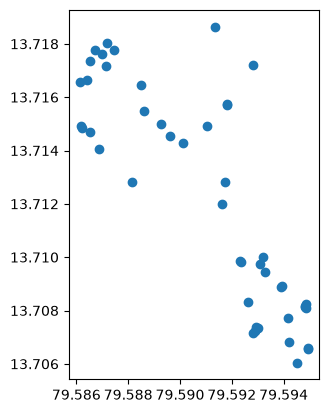

In [21]:
dustbins.plot()

## 6. Transform to a Projected CRS

In [22]:
dustbins_map = dustbins.to_crs(epsg=32644)

In [23]:
dustbins_map.crs

<Projected CRS: EPSG:32644>
Name: WGS 84 / UTM zone 44N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 78°E and 84°E, northern hemisphere between equator and 84°N, onshore and offshore. China. India. Kazakhstan. Kyrgyzstan. Nepal. Russian Federation. Sri Lanka.
- bounds: (78.0, 0.0, 84.0, 84.0)
Coordinate Operation:
- name: UTM zone 44N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

## 7. Create the Final Waste-Bin Map

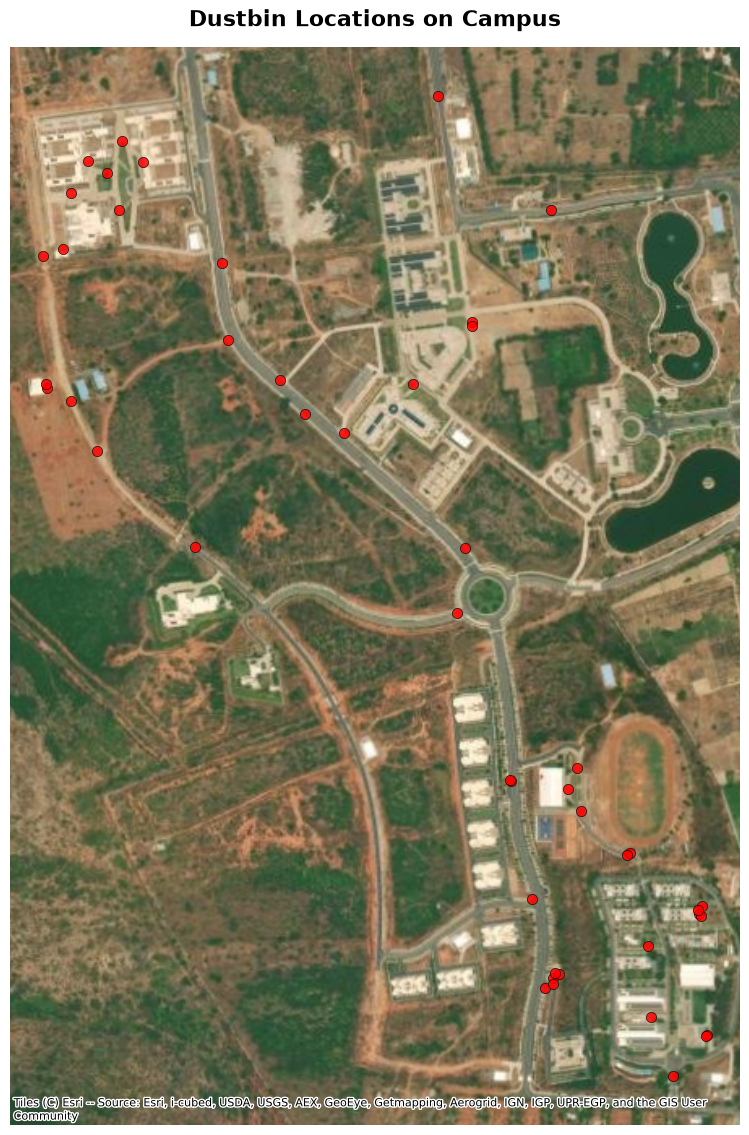

In [40]:
fig, ax = plt.subplots(figsize=(10, 14))

dustbins_map.plot(
    ax=ax,
    markersize=55,
    color="red",
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5
)

ctx.add_basemap(
    ax,
    crs=dustbins_map.crs,
    source=ctx.providers.Esri.WorldImagery
)

ax.set_title(
    "Dustbin Locations on Campus",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()

plt.show()

In [72]:
## north arrow
def add_north_arrow(ax, x=0.95, y=0.92):
    """Add a simple north arrow to a Matplotlib Axes."""
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.12),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold",
        arrowprops=dict(
            facecolor="black",
            edgecolor="black",
            width=4,
            headwidth=12
        )
    )

In [73]:
## scale bar 

def add_scale_bar(ax, length_m=200):
    """Add a simple scale bar when map coordinates are in metres."""
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    x_start = xmin + 0.07 * (xmax - xmin)
    y_start = ymin + 0.07 * (ymax - ymin)

    ax.plot(
        [x_start, x_start + length_m],
        [y_start, y_start],
        color="black",
        linewidth=4
    )

    if length_m >= 1000:
        label = f"{length_m / 1000:g} km"
    else:
        label = f"{length_m:g} m"

    ax.text(
        x_start + length_m / 2,
        y_start + 0.015 * (ymax - ymin),
        label,
        ha="center",
        va="bottom",
        fontsize=10
    )

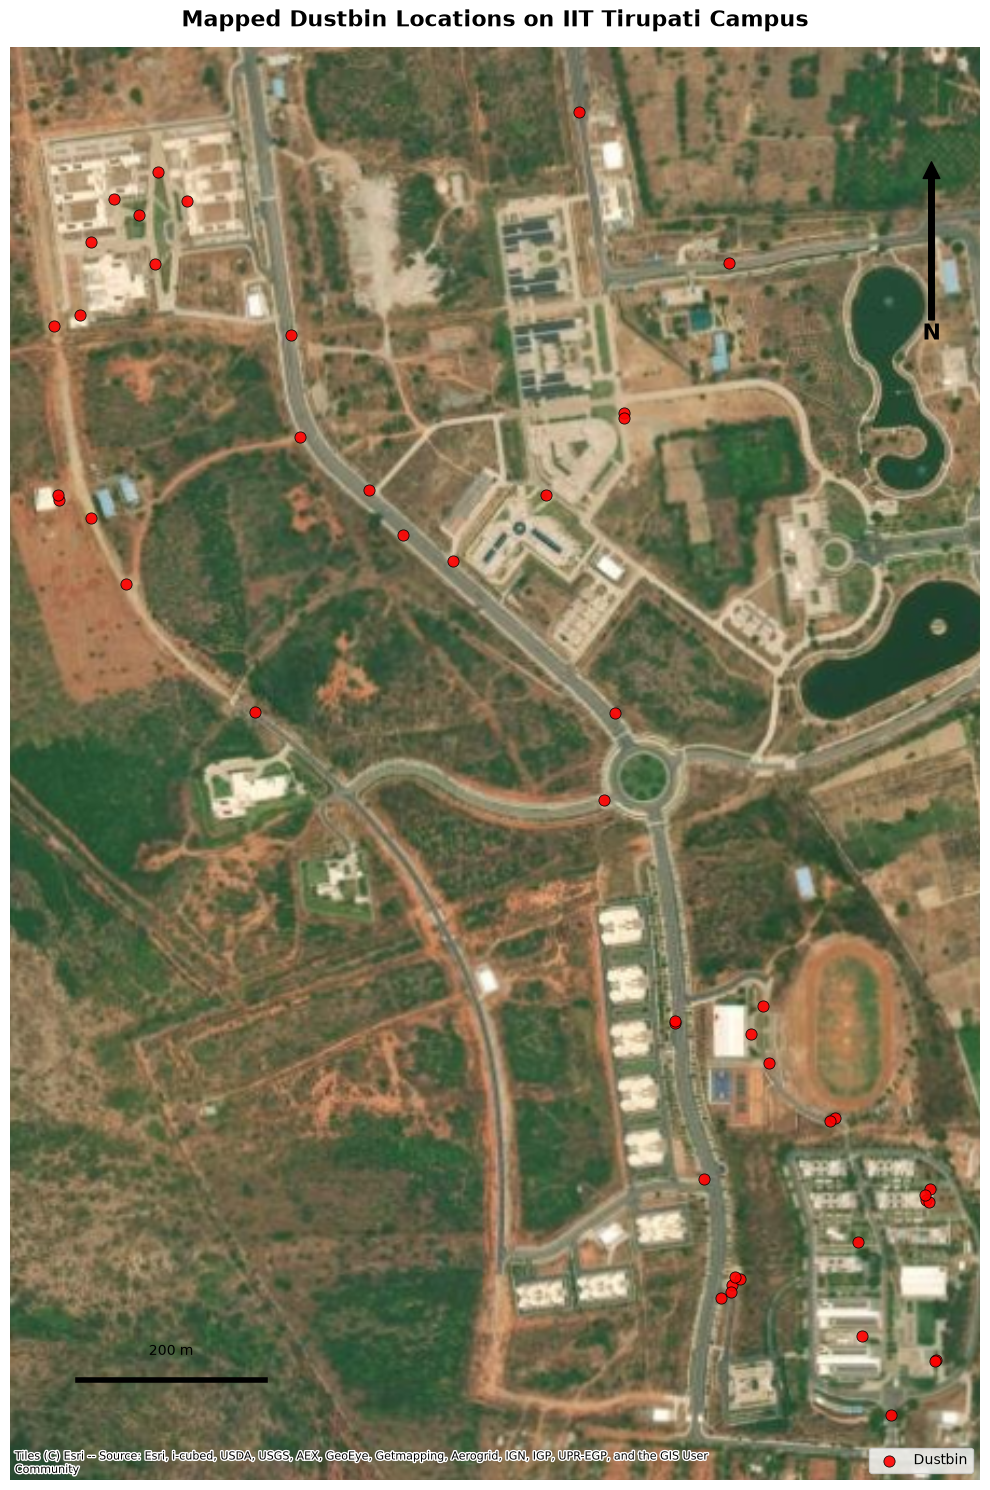

In [75]:
# plotting the final map
fig, ax = plt.subplots(figsize=(10, 16))

# Dustbin points
dustbins_map.plot(
    ax=ax,
    markersize=65,
    color="red",
    alpha=0.9,
    edgecolor="black",
    linewidth=0.6,
    label="Dustbin"
)

# Satellite basemap
ctx.add_basemap(
    ax,
    crs=dustbins_map.crs,
    source=ctx.providers.Esri.WorldImagery
)

# Title
ax.set_title(
    "Mapped Dustbin Locations on IIT Tirupati Campus",
    fontsize=16,
    fontweight="bold",
    pad=15
)

# Legend
ax.legend(loc="lower right")

# North arrow
add_north_arrow(ax)

# Scale bar
add_scale_bar(ax, length_m=200)

# Remove axes
ax.set_axis_off()

plt.tight_layout()

# export the map
plt.savefig(
    "HS25M101_Q1.png",
    dpi=300,
    bbox_inches="tight"
) 

plt.show()


# Q2. World Cities: Data Exploration, Filtering and Functions

This section analyses the provided `worldcities.csv` dataset using pandas.

The analysis includes:
1. Loading and inspecting the dataset
2. Exploring dataset dimensions and unique countries
3. Identifying the city with the highest population
4. Filtering cities with population greater than 10 million
5. Identifying Southern Hemisphere cities among the >10M cities
6. Finding the country with the largest number of >10M cities
7. Creating population bands using a custom function
8. Counting cities in each population band
9. Saving the updated dataset as a CSV file

## (a) Load and Explore the Dataset

In [76]:
## 1. Load the Dataset
import pandas as pd
cities = pd.read_csv(r"C:\Users\Ā\Documents\python_class\dataset\worldcities.csv")

In [77]:
### Display the first 5 rows
cities.head()

,city,city_ascii,lat,lng,country,iso2,iso3,admin_name,capital,population,id
0,Tokyo,Tokyo,35.6870,139.7495,Japan,JP,JPN,Tōkyō,primary,37785000.0,1392685764
1,Jakarta,Jakarta,-6.1750,106.8275,Indonesia,ID,IDN,Jakarta,primary,33756000.0,1360771077
2,Delhi,Delhi,28.6100,77.2300,India,IN,IND,Delhi,admin,32226000.0,1356872604
3,Guangzhou,Guangzhou,23.1300,113.2600,China,CN,CHN,Guangdong,admin,26940000.0,1156237133
4,Mumbai,Mumbai,19.0761,72.8775,India,IN,IND,Mahārāshtra,admin,24973000.0,1356226629


In [78]:
### Display the last 5 rows
cities.tail()

,city,city_ascii,lat,lng,country,iso2,iso3,admin_name,capital,population,id
48054,Al Jabīn,Al Jabin,14.7040,43.5990,Yemen,YE,YEM,Raymah,admin,NaN,1887910100
48055,Nelspruit,Nelspruit,-25.4745,30.9703,South Africa,ZA,ZAF,Mpumalanga,admin,NaN,1710114438
48056,Gqeberha,Gqeberha,-33.9681,25.5981,South Africa,ZA,ZAF,Eastern Cape,NaN,NaN,1710000082
48057,Lupane,Lupane,-18.9315,27.8070,Zimbabwe,ZW,ZWE,Matabeleland North,admin,NaN,1716206606
48058,Charlotte Amalie,Charlotte Amalie,18.3420,-64.9331,U.S. Virgin Islands,VI,VIR,Virgin Islands,primary,NaN,1850037473


In [79]:
### Display the shape of the dataset
cities.shape

(48059, 11)

In [94]:
### Count the number of unique countries

cities["country"].nunique()

242

In [95]:
### Identify the city with the highest population

cities.sort_values(
    "population",
    ascending=False
).head(1)

,city,city_ascii,lat,lng,country,iso2,iso3,admin_name,capital,population,id,pop_band
0,Tokyo,Tokyo,35.687,139.7495,Japan,JP,JPN,Tōkyō,primary,37785000.0,1392685764,Mega


## (b) Cities with Population Greater Than 10 Million

In [96]:
cities_over_10m = cities[
    cities["population"] > 10_000_000
]

In [97]:
### Display city, country and population
cities_over_10m[
    ["city", "country", "population"]
]

,city,country,population
0,Tokyo,Japan,37785000.0
1,Jakarta,Indonesia,33756000.0
2,Delhi,India,32226000.0
3,Guangzhou,China,26940000.0
4,Mumbai,India,24973000.0
5,Manila,Philippines,24922000.0
6,Shanghai,China,24073000.0
7,São Paulo,Brazil,23086000.0
8,Seoul,"Korea, South",23016000.0
9,Mexico City,Mexico,21804000.0


In [98]:
### Identify cities in the Southern Hemisphere

southern_hemisphere = cities_over_10m[
    cities_over_10m["lat"] < 0
]

southern_hemisphere[
    ["city", "country", "lat", "population"]
]

,city,country,lat,population
1,Jakarta,Indonesia,-6.1750,33756000.0
7,São Paulo,Brazil,-23.5504,23086000.0
19,Buenos Aires,Argentina,-34.6036,16710000.0
27,Kinshasa,Congo (Kinshasa),-4.3219,12836000.0
28,Rio de Janeiro,Brazil,-22.9111,12592000.0
41,Lima,Peru,-12.0600,10320000.0


In [99]:
### Identify the country with the largest number of cities above 10 million population

largest_country = cities_over_10m[
    "country"
].value_counts().head(1)

largest_country


country
China    12
Name: count, dtype: int64

In [100]:
### Identify the country name

largest_country_name = largest_country.index[0]

largest_country_name

'China'

In [101]:
### List the cities in that country and their populations

largest_country_cities = cities_over_10m[
    cities_over_10m["country"] == largest_country_name
]

largest_country_cities[
    ["city", "population"]
]

,city,population
3,Guangzhou,26940000.0
6,Shanghai,24073000.0
15,Beijing,18522000.0
17,Shenzhen,17619000.0
24,Chengdu,14645000.0
30,Xi’an,12328000.0
32,Chongqing,12135000.0
36,Linyi,10820000.0
37,Dongguan,10646000.0
38,Baoding,10546831.0


In [102]:
### Calculate the combined population of these cities

largest_country_cities["population"].sum()

np.float64(178893831.0)

## (c) Create Population Bands

In [103]:
### Define the population_band function

def population_band(pop):
    if pop < 100_000:
        return "Very Small"
    elif pop >= 100_000 and pop < 500_000:
        return "Small"
    elif pop >= 500_000 and pop < 2_000_000:
        return "Medium-Low"
    elif pop >= 2_000_000 and pop < 5_000_000:
        return "Medium-High"
    elif pop >= 5_000_000 and pop < 10_000_000:
        return "Large"
    else:
        return "Mega"

In [104]:
### Create the pop_band column

cities["pop_band"] = cities["population"].apply(population_band)

In [105]:
### Display the first 10 rows

cities.head(10)

,city,city_ascii,lat,lng,country,iso2,iso3,admin_name,capital,population,id,pop_band
0,Tokyo,Tokyo,35.6870,139.7495,Japan,JP,JPN,Tōkyō,primary,37785000.0,1392685764,Mega
1,Jakarta,Jakarta,-6.1750,106.8275,Indonesia,ID,IDN,Jakarta,primary,33756000.0,1360771077,Mega
2,Delhi,Delhi,28.6100,77.2300,India,IN,IND,Delhi,admin,32226000.0,1356872604,Mega
3,Guangzhou,Guangzhou,23.1300,113.2600,China,CN,CHN,Guangdong,admin,26940000.0,1156237133,Mega
4,Mumbai,Mumbai,19.0761,72.8775,India,IN,IND,Mahārāshtra,admin,24973000.0,1356226629,Mega
5,Manila,Manila,14.5958,120.9772,Philippines,PH,PHL,Manila,primary,24922000.0,1608618140,Mega
6,Shanghai,Shanghai,31.2286,121.4747,China,CN,CHN,Shanghai,admin,24073000.0,1156073548,Mega
7,São Paulo,Sao Paulo,-23.5504,-46.6339,Brazil,BR,BRA,São Paulo,admin,23086000.0,1076532519,Mega
8,Seoul,Seoul,37.5667,126.9833,"Korea, South",KR,KOR,Seoul,primary,23016000.0,1410836482,Mega
9,Mexico City,Mexico City,19.4333,-99.1333,Mexico,MX,MEX,Ciudad de México,primary,21804000.0,1484247881,Mega


In [106]:
### Count the frequency of cities in each population band

cities["pop_band"].value_counts()

pop_band
Very Small     41673
Small           4698
Medium-Low      1022
Mega             294
Medium-High      286
Large             86
Name: count, dtype: int64

In [107]:
### Save the updated DataFrame as a CSV

cities.to_csv(
    "HS25M101_Q2.csv",
    index=False
)